# Bài tập 1: Phân loại văn bản dựa trên KNN


Trong bài tập này, bạn được cung cấp một bộ dữ liệu về phân loại văn bản với hai nhãn `ham` và `spam`. Nội dung chính của các câu text liên quan đến tin nhắn điện thoại (SMS), với các câu có thể chứa nội dung bình thường (ham) hoặc các câu có dấu hiệu spam (spam). Các tin nhắn này có thể bao gồm những nội dung như thông báo, trò chuyện hàng ngày, hoặc các tin nhắn quảng cáo, mời chào không mong muốn.

Quá trình xây dựng mô hình phân loại trải qua các bước sau đây: 
1. Tiền xử lý dữ liệu: Làm sạch và chuẩn hóa văn bản.
2. Xây dựng từ điển (vocabulary): Tạo từ điển từ dữ liệu huấn luyện.
3. Chuyển đổi văn bản thành vector BoW: Biểu diễn mỗi tin nhắn dưới dạng vector.
4. Chia dữ liệu thành train / validation / test theo tỉ lệ 60% / 20% / 20%, giữ tỉ lệ nhãn bằng stratify
5. Sử dụng mô hình kNN để phân loại
6. Đánh giá mô hình: Sử dụng các chỉ số để đánh giá hiệu suất.

Các nội dung 1, 2, 3 là những nội dung hỗ trợ, bạn có thể đọc qua để hình dung về cách thực hiện. Các nội dung 4, 5, 6 là nội dung chính của bài tập, bạn hãy xem kĩ phần này nhé.
Ta chia dữ liệu trước khi học vocabulary. Chọn k và cách tiền xử lý bằng validation macro F1; chỉ dùng test sau khi đã chốt cấu hình.


## Tổng quan về dữ liệu

Như đã giới thiệu ở phía trên, bộ dữ liệu này chứa các câu text liên quan tới tin nhắn điện thoại và được phân loại vào một trong hai nhãn: `ham` và `spam`.

Nó có thể được sử dụng để phát triển mô hình phân loại tin nhắn rác, đặc biệt là phân loại tin nhắn SMS giữa spam và tin nhắn hợp lệ. Dữ liệu đa dạng với các câu text ngắn, chứa nhiều yếu tố gây nhiễu như icon, khoảng trắng dư thừa, dấu câu không cần thiết, và có thể có các từ không phù hợp cần làm sạch.

In [1]:
import pandas as pd
data_path = 'spam.csv'
data = pd.read_csv(data_path)
data.head(10)

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


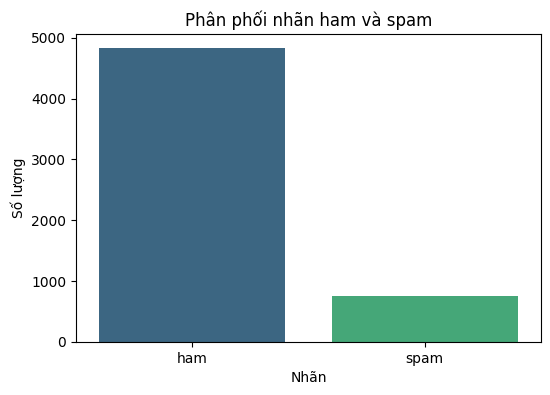

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Đếm số lượng `ham` và `spam`
label_counts = data['label'].value_counts().reset_index()
label_counts.columns = ['label', 'count']

# Vẽ biểu đồ thanh để hiển thị phân phối nhãn
plt.figure(figsize=(6,4))
sns.barplot(x='label', y='count', data=label_counts, palette='viridis', hue='label', dodge=False)
plt.title('Phân phối nhãn ham và spam')
plt.xlabel('Nhãn')
plt.ylabel('Số lượng') 
plt.legend([],[],frameon=False)  
plt.show()

## Làm sạch dữ liệu

Có thể thấy trong dữ liệu đã cho có nhiều chuỗi ký tự, dấu câu,... không có ý nghĩa. Do vậy ta cần thực hiện một bước làm sạch dữ liệu để nâng cao hiệu quả của mô hình. Các yếu tố cần làm sạch có thể là:

1. Ký tự đặc biệt: Các tin nhắn có thể chứa các ký tự đặc biệt không cần thiết như ..., !, ?, v.v.
2. Khoảng trắng thừa: Có thể xuất hiện các khoảng trắng thừa giữa các từ hoặc ở đầu/cuối câu.
3. Icon và biểu tượng: Có thể có các icon hoặc biểu tượng đặc biệt cần loại bỏ.
4. Chữ viết tắt hoặc từ lóng: Các từ viết tắt cần được chuẩn hóa thành dạng đầy đủ.
5. Dấu câu không cần thiết: Dấu chấm câu có thể gây nhiễu khi xử lý văn bản.

Dưới đây implement một hàm đơn giản để xử lý sơ bộ dữ liệu đã cho. Nếu muốn, bạn cũng có thể bổ sung thêm logic để xử lý các trường hợp khác.

In [3]:
import re

# Hàm xử lý văn bản
def clean_text(text):
    # Chuyển thành chữ thường
    text = text.lower()
    # Loại bỏ các ký tự đặc biệt, dấu chấm câu
    text = re.sub(r'[^a-z\s]', '', text)
    # Loại bỏ khoảng trắng thừa
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Áp dụng hàm clean_text lên cột 'text'
data['cleaned_text'] = data['text'].apply(clean_text)

# Hiển thị dữ liệu đã được làm sạch
data.head(10)

,label,text,cleaned_text
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now a...
6,ham,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,ham,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,spam,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,spam,Had your mobile 11 months or more? U R entitle...,had your mobile months or more u r entitled to...


## Xây dựng vocabulary 

### Giới thiệu về vocabulary trong ngữ cảnh Xử lý ngôn ngữ tự nhiên

Vocabulary (từ điển) trong xử lý ngôn ngữ tự nhiên (NLP) là tập hợp tất cả các từ duy nhất xuất hiện trong một tập dữ liệu văn bản. Mỗi từ trong vocabulary đại diện cho một "từ khóa" và được ánh xạ đến một chỉ số duy nhất, từ đó chuyển đổi các từ ngữ trong văn bản thành dạng số học để mô hình có thể xử lý.

Trong các mô hình dựa trên văn bản như k-Nearest Neighbors (kNN), Naive Bayes, hoặc các mô hình học sâu, việc xây dựng một vocab là bước đầu tiên để biến đổi văn bản thành dạng vector số, giúp các thuật toán học máy có thể làm việc.

### Ví dụ minh họa

Giả sử chúng ta có tập dữ liệu văn bản với các câu như sau:

```python
documents = [
    "I love programming.",
    "Programming is fun.",
    "I love learning new things."
]
```

**Bước 1: Tiền xử lý văn bản**

Chúng ta làm sạch dữ liệu bằng cách:
- Chuyển thành chữ thường: `"I love programming." → "i love programming."`
- Loại bỏ dấu câu: `"i love programming." → "i love programming"`

**Bước 2: Tạo danh sách các từ**
Tách từng câu thành các từ riêng lẻ:
- Câu 1: `["i", "love", "programming"]`
- Câu 2: `["programming", "is", "fun"]`
- Câu 3: `["i", "love", "learning", "new", "things"]`

Loại bỏ từ trùng lặp:
- Danh sách từ duy nhất: `["i", "love", "programming", "is", "fun", "learning", "new", "things"]`

**Bước 3: Đánh chỉ số cho các từ**
Chúng ta gán một chỉ số cho mỗi từ duy nhất:
- `"i"`: 0
- `"love"`: 1
- `"programming"`: 2
- `"is"`: 3
- `"fun"`: 4
- `"learning"`: 5
- `"new"`: 6
- `"things"`: 7

Vocabulary sẽ được biểu diễn như sau:

```python
vocabulary = {
    "i": 0,
    "love": 1,
    "programming": 2,
    "is": 3,
    "fun": 4,
    "learning": 5,
    "new": 6,
    "things": 7
}
```


In [4]:
from sklearn.model_selection import train_test_split

# Tránh trùng tin nhắn giữa các tập dữ liệu sau khi làm sạch
data = data.drop_duplicates(subset='cleaned_text').reset_index(drop=True)
X = data['cleaned_text']
y = data['label']

# Dữ liệu mất cân bằng: dùng stratify để giữ tỉ lệ ham/spam
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25,
    random_state=42, stratify=y_train_full
)

# Chỉ học vocabulary từ tập train, không dùng validation hoặc test
def build_vocabulary(texts):
    vocab = {}
    for text in texts:
        for word in text.split():
            if word not in vocab:
                vocab[word] = len(vocab)
    return vocab

vocabulary = build_vocabulary(X_train)
print('Train / validation / test:', len(X_train), len(X_val), len(X_test))


Train / validation / test: 3054 1018 1019


In [5]:
print(f"Kích thước từ điển: {len(vocabulary)}")

print("Một số từ trong từ điển:")
for item in list(vocabulary.items())[:20]:
    print(item)


Kích thước từ điển: 6303
Một số từ trong từ điển:
('most', 0)
('of', 1)
('the', 2)
('tiime', 3)
('when', 4)
('i', 5)
('dont', 6)
('let', 7)
('you', 8)
('hug', 9)
('me', 10)
('its', 11)
('so', 12)
('break', 13)
('into', 14)
('tears', 15)
('fetch', 16)
('yun', 17)
('or', 18)
('u', 19)


**Vocabulary học từ tập train có 6303 từ; đây là số chiều của vector BoW trong giai đoạn chọn mô hình.**

## Chuyển đổi văn bản thành vector bằng kỹ thuật BoW 

### Giới thiệu kỹ thuật Bag of Words (BoW)

**Bag of Words (BoW)** là một kỹ thuật đơn giản để biểu diễn văn bản trong xử lý ngôn ngữ tự nhiên (NLP). Kỹ thuật này chuyển đổi văn bản thành một vector số, trong đó mỗi phần tử của vector đại diện cho số lần xuất hiện của một từ trong từ điển (vocabulary). 

Trong mô hình BoW, thứ tự của các từ không được xem xét, mà chỉ quan tâm đến tần suất xuất hiện của các từ.

### Ví dụ minh họa

Giả sử chúng ta đã có vocabulary như sau:

```python
vocabulary = {
    "i": 0,
    "love": 1,
    "programming": 2,
    "is": 3,
    "fun": 4,
    "learning": 5,
    "new": 6,
    "things": 7
}
```

Bây giờ, chúng ta sẽ chuyển đổi các câu văn bản thành vector sử dụng BoW.

#### Văn bản:

```python
documents = [
    "I love programming",
    "Programming is fun",
    "I love learning new things"
]
```

Sử dụng kỹ thuật BoW, các câu trên sẽ được biểu diễn thành vector như sau:

- `"I love programming"` → `[1, 1, 1, 0, 0, 0, 0, 0]`
- `"Programming is fun"` → `[0, 0, 1, 1, 1, 0, 0, 0]`
- `"I love learning new things"` → `[1, 1, 0, 0, 0, 1, 1, 1]`

### Giải thích:

- Mỗi phần tử trong vector tương ứng với một từ trong vocabulary.
- Các giá trị trong vector biểu diễn số lần xuất hiện của từ tương ứng trong câu.
- Kỹ thuật BoW không quan tâm đến thứ tự từ, chỉ quan tâm đến tần suất từ.

BoW là một phương pháp đơn giản để biểu diễn văn bản, đặc biệt hữu ích trong các bài toán phân loại văn bản như xác định `ham` hay `spam`.

In [6]:
import numpy as np

def text_to_vector(text, vocab):
    vector = np.zeros(len(vocab))
    for word in text.split():
        if word in vocab:
            index = vocab[word]
            vector[index] += 1
    return vector

## Xây dựng mô hình kNN để phân loại tin nhắn 

4. Chia dữ liệu thành train / validation / test theo tỉ lệ 60% / 20% / 20%, giữ tỉ lệ nhãn bằng stratify
5. Sử dụng mô hình kNN để phân loại
6. Đánh giá mô hình: Sử dụng các chỉ số để đánh giá hiệu suất.

In [7]:
from sklearn.neighbors import KNeighborsClassifier

# Chuyển đổi tất cả các văn bản trong tập huấn luyện và validation
X_train_vectors = np.array([text_to_vector(text, vocabulary) for text in X_train])
X_val_vectors = np.array([text_to_vector(text, vocabulary) for text in X_val])

knn = KNeighborsClassifier(n_neighbors=5)

# Xây dựng mô hình kNN từ `X_train_vectors` và `y_train`
### START CODE HERE
knn.fit(X_train_vectors, y_train)
### END CODE HERE


# Dự đoán nhãn từ tập validation
### START CODE HERE
y_pred = knn.predict(X_val_vectors)
### END CODE HERE

In [8]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

def test_report(y_true, y_pred):
    print(classification_report(y_true, y_pred, zero_division=0))
    print('Accuracy:', accuracy_score(y_true, y_pred))
    print('Macro F1:', f1_score(y_true, y_pred, average='macro'))

print('Kết quả validation với k = 5:')
test_report(y_val, y_pred)


Kết quả validation với k = 5:
              precision    recall  f1-score   support

         ham       0.93      1.00      0.96       899
        spam       1.00      0.40      0.57       119

    accuracy                           0.93      1018
   macro avg       0.96      0.70      0.77      1018
weighted avg       0.94      0.93      0.92      1018

Accuracy: 0.9302554027504911
Macro F1: 0.7684310352008663


Thử k trong `[1, 3, 5, 7]` trên tập validation. Hoàn thành hàm trả về dict ánh xạ mỗi k tới macro F1 tương ứng, rồi chọn k có macro F1 cao nhất. Ham chiếm khoảng 88% dữ liệu sau khi loại trùng, nên accuracy có thể che giấu việc bỏ sót spam. Không dùng tập test ở bước này.

In [9]:
def run_knn_with_multiple_k(X_train, X_val, y_train, y_val, k_values):
    """Trả về dict {k: macro F1 trên validation}; không sử dụng tập test."""
    validation_scores = {}
    ### START CODE HERE ###
    for k in k_values:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        validation_scores[k] = f1_score(y_val, y_pred, average='macro')
    ### END CODE HERE ###
    return validation_scores

k_values = [1, 3, 5, 7]
validation_scores = run_knn_with_multiple_k(
    X_train_vectors, X_val_vectors, y_train, y_val, k_values
)
best_k = max(validation_scores, key=validation_scores.get)
print('Macro F1 trên validation:', validation_scores)
print('k được chọn:', best_k)


Macro F1 trên validation: {1: 0.8691169511137615, 3: 0.8211136096260667, 5: 0.7684310352008663, 7: 0.6996518557856848}
k được chọn: 1


## Tổng kết

Trong bài tập này, bạn đã được giới thiệu về cách sử dụng thuật toán `kNN` cho bài toán phân loại văn bản. Bên cạnh đó, một số kỹ thuật đơn giản để xử lý văn bản, xây dựng vocabulary, chuyển text thành vector cũng được đề cập đến. Đây đều là những kỹ thuật căn bản phù hợp với người mới bắt đầu, do vậy có thể độ hiệu quả mà các kỹ thuật này mang lại chưa cao. Chẳng hạn như với kỹ thuật BoW, mỗi vector biểu diễn text được tạo ra có độ dài bằng với số phần tử trong vocab, trong bài toán này vocab có độ dài $6303$ nên mỗi vector cũng có độ dài $6303$, khi đưa các vector này vào những mô hình phức tạp hơn có thể làm cho quá trình huấn luyện hoặc dự đoán bị chậm đi rất nhiều. Đây cũng là động lực để các nhà nghiên cứu tìm ra các phương pháp chuyển văn bản thành vector hiệu quả hơn.

# Bài tập 2: Loại bỏ stop words trong văn bản 

Stop words thường là những từ phổ biến mang ít thông tin phân loại. Trong bài tập này, ta thử một **heuristic lọc từ có giám sát**: so sánh tỉ lệ số lần xuất hiện của từ trong ham/spam với tỉ lệ nhãn của các tin nhắn trong tập train. Hai loại tỉ lệ này không hoàn toàn giống nhau; các từ bị loại không nhất thiết là stop words theo nghĩa thông thường.

Ta giữ **best_k đã chọn ở Bài tập 1**, rồi thử các threshold để xem kích thước vocabulary và chất lượng dự đoán thay đổi ra sao. Vocabulary nhỏ hơn có thể tiết kiệm tài nguyên, nhưng có thể loại mất thông tin hữu ích; không đảm bảo nhanh hơn hoặc dự đoán tốt hơn. Mọi lựa chọn dùng validation macro F1, không dùng test.


## Bước 1: Tính tỉ lệ ham và spam trong toàn bộ tập train

In [10]:
ham_spam_ratio = y_train.value_counts()/sum(y_train.value_counts())

print("Tỷ lệ giữa nhãn ham và spam trong tập huấn luyện:")
ham_spam_ratio

Tỷ lệ giữa nhãn ham và spam trong tập huấn luyện:

label
ham     0.883432
spam    0.116568
Name: count, dtype: float64


## Bước 2: Tính tỉ lệ của từng từ trong từ điển

In [11]:
def calculate_word_frequency(vocabulary, texts, labels):
    """
    Tính tần suất xuất hiện của từng từ trong văn bản ham và spam
    Arguments:
    - vocabulary: từ điển chứa các từ và chỉ số tương ứng
    - texts: list chứa các văn bản của tập dữ liệu
    - labels: list chứa nhãn tương ứng của các văn bản tương ứng trong `texts`
    Output:
    - word_ham_spam_counts: từ điển chứa tần suất xuất hiện của từng từ trong văn bản ham và spam
    Example:
        Input:
            vocabulary = {'word1': 0, 'word2': 1, 'word3': 2}
            texts = ['word1 word2', 'word2 word3', 'word1']
            labels = ['ham', 'spam', 'spam']
        Output:
            {
                'word1': {'ham': 1, 'spam': 1, 'total': 2},
                'word2': {'ham': 1, 'spam': 1, 'total': 2},
                'word3': {'ham': 0, 'spam': 1, 'total': 1}
            }
    """
    word_ham_spam_counts = vocabulary.copy()
    for word in word_ham_spam_counts:
        word_ham_spam_counts[word] = {'ham': 0, 'spam': 0, 'total':0}

    ### START CODE HERE
    for text, label in zip(texts, labels):
        for word in text.split():
            word_ham_spam_counts[word][label] += 1
            word_ham_spam_counts[word]['total'] += 1
    return word_ham_spam_counts
    ### END CODE HERE
    
word_ham_spam_counts = calculate_word_frequency(vocabulary, X_train, y_train)
# Hiển thị tần suất xuất hiện của một số từ
for word in list(vocabulary.keys())[:10]:
    print(f"{word}: {word_ham_spam_counts[word]}")

most: {'ham': 16, 'spam': 1, 'total': 17}
of: {'ham': 293, 'spam': 45, 'total': 338}
the: {'ham': 582, 'spam': 98, 'total': 680}
tiime: {'ham': 1, 'spam': 0, 'total': 1}
when: {'ham': 150, 'spam': 4, 'total': 154}
i: {'ham': 1268, 'spam': 20, 'total': 1288}
dont: {'ham': 132, 'spam': 12, 'total': 144}
let: {'ham': 38, 'spam': 0, 'total': 38}
you: {'ham': 1067, 'spam': 126, 'total': 1193}
hug: {'ham': 4, 'spam': 0, 'total': 4}


In [12]:
assert word_ham_spam_counts['no']['ham'] == 146
assert word_ham_spam_counts['im']['spam'] == 10
assert word_ham_spam_counts['same']['ham'] == 26

In [13]:
# Tính tỉ lệ giữa số lần xuất hiện của từng từ trong văn bản ham và spam
word_ham_spam_ratios = {}
for word, counts in word_ham_spam_counts.items():
    word_ham_spam_ratios[word] = {'ham': (counts['ham'])/(counts['total']),
                                    'spam': (counts['spam'])/(counts['total'])}
# Hiển thị tỉ lệ của một số từ
for word in list(vocabulary.keys())[:10]:
    print(f"{word}: {word_ham_spam_ratios[word]}")

most: {'ham': 0.9411764705882353, 'spam': 0.058823529411764705}
of: {'ham': 0.8668639053254438, 'spam': 0.13313609467455623}
the: {'ham': 0.8558823529411764, 'spam': 0.14411764705882352}
tiime: {'ham': 1.0, 'spam': 0.0}
when: {'ham': 0.974025974025974, 'spam': 0.025974025974025976}
i: {'ham': 0.984472049689441, 'spam': 0.015527950310559006}
dont: {'ham': 0.9166666666666666, 'spam': 0.08333333333333333}
let: {'ham': 1.0, 'spam': 0.0}
you: {'ham': 0.8943839061190276, 'spam': 0.10561609388097234}
hug: {'ham': 1.0, 'spam': 0.0}


## Bước 3: Loại bỏ stop words

Sau khi tính toán tỉ lệ ham và spam của từng từ, chúng ta sẽ so sánh tỉ lệ này với tỉ lệ ham và spam trong tập huấn luyện.

Ý tưởng: Nếu một từ xuất hiện trong ham và spam với tỉ lệ gần giống tỉ lệ tổng thể, thì từ đó không có khả năng phân biệt giữa hai loại văn bản → coi là stop word.

Cách tính khoảng cách: Sử dụng giá trị tuyệt đối của hiệu số giữa tỉ lệ ham của từ và tỉ lệ ham tổng thể:

```
distance = |word_ham_ratio - overall_ham_ratio|
```

Tiêu chí: Nếu `distance < threshold`, ta coi từ đó là stop word.

Ví dụ minh họa:
- Giả sử tỉ lệ tổng thể: ham = 0.87, spam = 0.13
- Từ "the": ham = 0.85, spam = 0.15 → distance = |0.85 - 0.87| = 0.02 < 0.2 → stop word
- Từ "free": ham = 0.10, spam = 0.90 → distance = |0.10 - 0.87| = 0.77 > 0.2 → không phải stop word
- Từ "urgent": ham = 0.20, spam = 0.80 → distance = |0.20 - 0.87| = 0.67 > 0.2 → không phải stop word

In [14]:
def find_stop_word(ham_spam_ratio, word_ham_spam_ratios, threshold=0.1):
    """
    Tìm stop words dựa trên tỉ lệ giữa số lần xuất hiện của từ trong văn bản ham và spam so với tỉ lệ giữa ham và spam trong tập huấn luyện
    
    Nguyên tắc: Nếu tỉ lệ ham của một từ gần với tỉ lệ ham tổng thể (khoảng cách nhỏ hơn threshold),
    thì từ đó xuất hiện đồng đều trong cả ham và spam → không phân biệt được → stop word.
    
    Arguments:
    - ham_spam_ratio: tỉ lệ giữa nhãn ham và spam trong tập huấn luyện (ví dụ: {'ham': 0.87, 'spam': 0.13})
    - word_ham_spam_ratios: từ điển chứa tỉ lệ giữa số lần xuất hiện của từ trong văn bản ham và spam
    - threshold: ngưỡng để xác định stop words (khoảng cách tối đa được chấp nhận)
    
    Output:
    - stop_words: list chứa các stop words
    
    Example:
        Input:
            ham_spam_ratio = {'ham': 0.6, 'spam': 0.4}
            word_ham_spam_ratios = {
                'word1': {'ham': 0.5, 'spam': 0.5},  # |0.5 - 0.6| = 0.1 → stop word nếu threshold > 0.1 (điều kiện dùng dấu <)
                'word2': {'ham': 0.62, 'spam': 0.38}, # |0.62 - 0.6| = 0.02 → stop word
                'word3': {'ham': 0.9, 'spam': 0.1}    # |0.9 - 0.6| = 0.3 → không phải stop word
            }
            threshold = 0.15
        Output:
            ['word1', 'word2']  # Chỉ word1 và word2 có khoảng cách < 0.15
        
        Giải thích:
        - word1: khoảng cách = |0.5 - 0.6| = 0.1 < 0.15 → stop word
        - word2: khoảng cách = |0.62 - 0.6| = 0.02 < 0.15 → stop word  
        - word3: khoảng cách = |0.9 - 0.6| = 0.3 > 0.15 → KHÔNG phải stop word (từ phân biệt rõ)
    """
    ### START CODE HERE
    ham_ratio = ham_spam_ratio['ham']
    stop_words = []
    for word, ratios in word_ham_spam_ratios.items():
        if abs(ratios['ham'] - ham_ratio) < threshold:
            stop_words.append(word)
    return stop_words
    ### END CODE HERE

example_threshold = 0.2 # Chỉ minh họa; không phải threshold được chọn cuối cùng
stop_words = find_stop_word(ham_spam_ratio, word_ham_spam_ratios, example_threshold)
print(f"Số lượng stop words: {len(stop_words)}")
print("Một số stop words:")
print(stop_words[:10])

Số lượng stop words: 4913
Một số stop words:
['most', 'of', 'the', 'tiime', 'when', 'i', 'dont', 'let', 'you', 'hug']


In [15]:
assert stop_words[:7] == ['most', 'of', 'the', 'tiime', 'when', 'i', 'dont']

In [16]:
# Chúng ta sẽ loại bỏ stop words khỏi từ điển
new_vocabulary = vocabulary.copy()
for word in stop_words:
    new_vocabulary.pop(word)
# Và chúng ta sẽ đánh index lại cho từ điển
new_vocabulary = {word: idx for idx, word in enumerate(new_vocabulary.keys())}

print(f"Kích thước từ điển sau khi loại bỏ stop words: {len(new_vocabulary)}")

Kích thước từ điển sau khi loại bỏ stop words: 1390


In [17]:
assert len(new_vocabulary) == 1390

## Bước 4: Tuning threshold trên validation

Ví dụ threshold = 0.2 phía trên chỉ minh họa cách lọc và kiểm tra hàm. Bây giờ hãy hoàn thành `run_knn_with_thresholds` với `[0.02, 0.04, 0.07, 0.1, 0.2]`.

Giữ nguyên `best_k` từ Bài tập 1. Tính thống kê từ trên train một lần; với mỗi threshold, tạo vocabulary mới, vector hóa train/validation, huấn luyện và ghi lại kích thước vocabulary, phần trăm giảm, validation macro F1 và recall của spam. Không gọi lại hàm tìm k. Không thay đổi vocabulary gốc.

Chọn theo validation macro F1 và so sánh với baseline không lọc. Baseline được giữ nếu bằng điểm; nếu các threshold bằng điểm, lấy threshold đầu tiên trong danh sách tăng dần. Không dùng kích thước vocabulary hoặc spam recall để thay đổi tiêu chí chọn trong bài này.


In [18]:
print('Vocabulary gốc:', len(vocabulary))
X_train_vectors = np.array([text_to_vector(text, vocabulary) for text in X_train])
X_val_vectors = np.array([text_to_vector(text, vocabulary) for text in X_val])
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_vectors, y_train)
y_pred = knn.predict(X_val_vectors)
print('Validation, không loại stop words:')
test_report(y_val, y_pred)


Vocabulary gốc: 6303
Validation, không loại stop words:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       899
        spam       0.95      0.64      0.76       119

    accuracy                           0.95      1018
   macro avg       0.95      0.82      0.87      1018
weighted avg       0.95      0.95      0.95      1018

Accuracy: 0.9538310412573674
Macro F1: 0.8691169511137615


In [19]:
from sklearn.metrics import recall_score

def run_knn_with_thresholds(X_train, X_val, y_train, y_val, vocabulary, thresholds, best_k):
    """
    Giữ nguyên best_k từ Bài tập 1, so sánh các threshold trên validation.
    Chỉ dùng X_train và y_train để tính tần suất, tỉ lệ và stop words.
    Trả về DataFrame với các cột: threshold, vocab_size, reduction_pct,
    validation_macro_f1, spam_recall; giữ thứ tự của thresholds.
    Mỗi vocabulary mới phải được đánh lại index từ 0; không sửa vocabulary gốc.
    """
    ### START CODE HERE
    counts = calculate_word_frequency(vocabulary, X_train, y_train)
    word_ratios = {
        word: {label: values[label] / values['total'] for label in ['ham', 'spam']}
        for word, values in counts.items()
    }
    class_ratio = y_train.value_counts(normalize=True)
    results = []
    for threshold in thresholds:
        removed = set(find_stop_word(class_ratio, word_ratios, threshold))
        filtered_vocabulary = {
            word: idx for idx, word in enumerate(
                word for word in vocabulary if word not in removed
            )
        }
        train_vectors = np.array([text_to_vector(text, filtered_vocabulary) for text in X_train])
        val_vectors = np.array([text_to_vector(text, filtered_vocabulary) for text in X_val])
        model = KNeighborsClassifier(n_neighbors=best_k)
        model.fit(train_vectors, y_train)
        predictions = model.predict(val_vectors)
        results.append({
            'threshold': threshold,
            'vocab_size': len(filtered_vocabulary),
            'reduction_pct': 100 * (1 - len(filtered_vocabulary) / len(vocabulary)),
            'validation_macro_f1': f1_score(y_val, predictions, average='macro'),
            'spam_recall': recall_score(y_val, predictions, pos_label='spam', zero_division=0)
        })
    return pd.DataFrame(results)
    ### END CODE HERE

thresholds = [0.02, 0.04, 0.07, 0.1, 0.2]
threshold_results = run_knn_with_thresholds(
    X_train, X_val, y_train, y_val, vocabulary, thresholds, best_k
)
print(threshold_results.to_string(index=False))

# Chọn theo validation macro F1; baseline thắng nếu bằng điểm.
baseline_score = validation_scores[best_k]
best_row = threshold_results.loc[threshold_results['validation_macro_f1'].idxmax()]
selected_threshold = None
if best_row['validation_macro_f1'] > baseline_score:
    selected_threshold = float(best_row['threshold'])
print('k cố định:', best_k)
print('Threshold được chọn (None = không lọc):', selected_threshold)


 threshold  vocab_size  reduction_pct  validation_macro_f1  spam_recall
      0.02        6248       0.872600             0.882514     0.655462
      0.04        6180       1.951452             0.879172     0.647059
      0.07        6100       3.220689             0.871211     0.621849
      0.10        6009       4.664446             0.853493     0.579832
      0.20        1390      77.947009             0.831051     0.529412
k cố định: 1
Threshold được chọn (None = không lọc): 0.02


## Tổng kết và câu hỏi thảo luận

1. Threshold cho vocabulary nhỏ nhất có cho validation macro F1 tốt nhất không?
2. Recall của spam thay đổi thế nào khi lọc mạnh hơn? Kích thước vocabulary có đủ để kết luận về thời gian chạy hay bộ nhớ không?
3. Vì sao một cấu hình tốt hơn trên validation có thể kém hơn trên test?
4. Vì sao cần báo cáo kết quả test thay vì tiếp tục đổi threshold để tăng điểm test?

Ta tuning tuần tự: chọn k trước, giữ k cố định rồi chọn threshold. Đây không phải tìm kiếm đồng thời tất cả cặp (k, threshold). Một lần chia dữ liệu cũng chưa đủ để khẳng định cấu hình tốt nhất trong thực tế.


## Đánh giá cuối cùng trên tập test

Giữ best_k và selected_threshold đã chọn bằng validation. Học lại vocabulary và mô hình trên train + validation (80%). Nếu selected_threshold khác None, tính lại thống kê từ và lọc bằng threshold đó chỉ trên train + validation. Đánh giá cấu hình đã chọn một lần trên test (20%); không dùng điểm test để chọn lại k, threshold hoặc tiền xử lý. Vocabulary cuối có thể khác vocabulary dùng lúc validation vì tập huấn luyện đã lớn hơn.


In [20]:
# Cấu hình đã được chọn bằng validation; không chọn lại k ở đây.
final_k = best_k
final_vocabulary = build_vocabulary(X_train_full)

if selected_threshold is not None:
    final_counts = calculate_word_frequency(final_vocabulary, X_train_full, y_train_full)
    final_ratios = {
        word: {label: counts[label] / counts['total'] for label in ['ham', 'spam']}
        for word, counts in final_counts.items()
    }
    final_class_ratio = y_train_full.value_counts(normalize=True)
    final_stop_words = set(find_stop_word(final_class_ratio, final_ratios, selected_threshold))
    final_vocabulary = {
        word: idx for idx, word in enumerate(
            word for word in final_vocabulary if word not in final_stop_words
        )
    }

X_train_full_vectors = np.array([text_to_vector(text, final_vocabulary) for text in X_train_full])
X_test_vectors = np.array([text_to_vector(text, final_vocabulary) for text in X_test])
final_model = KNeighborsClassifier(n_neighbors=final_k)
final_model.fit(X_train_full_vectors, y_train_full)
final_predictions = final_model.predict(X_test_vectors)
print('Cấu hình cuối: k =', final_k, '; threshold =', selected_threshold)
print('Kích thước vocabulary cuối:', len(final_vocabulary))
test_report(y_test, final_predictions)


Cấu hình cuối: k = 1 ; threshold = 0.02
Kích thước vocabulary cuối: 7295
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       900
        spam       1.00      0.55      0.71       119

    accuracy                           0.95      1019
   macro avg       0.97      0.77      0.84      1019
weighted avg       0.95      0.95      0.94      1019

Accuracy: 0.9470068694798822
Macro F1: 0.8386977627691009


### Giải thích kết quả tham khảo

Với cách chia cố định và môi trường của khóa học, Bài tập 1 chọn k = 1. Khi giữ k này, threshold = 0.02 cho validation macro F1 khoảng 0.8825, cao hơn baseline 0.8691; vocabulary giảm từ 6303 xuống 6248 từ.

Sau khi học lại trên train + validation, vocabulary được lọc còn 7295 từ. Test accuracy khoảng 94.70%, macro F1 khoảng 0.8387 và recall spam khoảng 54.62%. Trong phép so sánh baseline đã thực hiện trước đó trên cùng test, macro F1 là 0.8462 và recall spam 56.30%; cấu hình lọc bỏ sót thêm hai tin spam. Đây là so sánh tham khảo, không phải lý do để chọn lại cấu hình sau khi xem test.

Validation và test là những mẫu khác nhau; vocabulary và thống kê từ cũng được học lại trên nhiều dữ liệu hơn. Do đó cải thiện trên validation không đảm bảo cải thiện trên test. Chênh lệch nhỏ của một lần chia chưa chứng minh ưu thế có ý nghĩa thống kê. Quy trình chọn có thể đúng dù điểm test của cấu hình được chọn thấp hơn baseline. Muốn đánh giá ổn định hơn, có thể dùng cross-validation trên dữ liệu phát triển và một tập test độc lập cho đánh giá cuối.
